# Explorer les détections et les groupes de visages

**Owner:** Data Team DataForGood  
**Dernière révision:** 2026-10-16  
**Status:** expérimental

Exploration issue de la PR 27, adaptée à la pipeline actuelle. Comparer les crops, les filtres et les groupes sur un film. Aucun résultat de qualité n'est établi par ce notebook.

Depuis la racine du dépôt, préparer le noyau dédié :

```bash
bash ml-image/install/setup_local.sh
uv pip install --python ml-image/.venv/bin/python ipykernel
ml-image/.venv/bin/python -m ipykernel install --user --name ric-ml-cpu --display-name "RIC ML (Python 3.11 CPU)"
```

Dans Jupyter ou VS Code, sélectionner **RIC ML (Python 3.11 CPU)**, puis redémarrer le noyau et exécuter toutes les cellules. Si le noyau nommé n’apparaît pas dans VS Code, choisir directement `ml-image/.venv/bin/python`. Le `.venv` à la racine du dépôt est distinct et peut ne pas contenir OpenCV (`cv2`) ni les modèles ML.

Préparer les poids selon le README ML. Lancer depuis la racine du dépôt, `ml-image/` ou `ml-image/notebooks/`. Toutes les images vidéo sont chargées : utiliser un extrait court. Les modèles peuvent télécharger leurs poids manquants. MediaPipe peut nécessiter un contexte graphique.

Comparer d'abord une exécution sans expansion ni suppression, puis modifier une option. Inspecter les crops et les groupes ; une meilleure similarité des distributions ne prouve pas une meilleure classification.

In [1]:
from pathlib import Path
import os
import sys
import tempfile
import importlib.util

here = Path.cwd().resolve()
ROOT = next((p / 'ml-image' if (p / 'ml-image/scripts').is_dir() else p
             for p in [here, *here.parents]
             if (p / 'ml-image/scripts').is_dir() or (p.name == 'ml-image' and (p / 'scripts').is_dir())), None)
if ROOT is None:
    raise RuntimeError('Lancer depuis le dépôt RIC')
# Vérifier le noyau avant les imports lourds et toute modification du répertoire.
print('Python actif :', sys.executable)
required_modules = ['cv2', 'numpy', 'pandas', 'matplotlib', 'torch', 'mediapipe',
                    'ultralytics', 'facenet_pytorch', 'dlib', 'loguru', 'IPython']
missing = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(
        f"Dépendances ML absentes : {', '.join(missing)}. "
        f"Noyau actif : {sys.executable}. "
        f"Sélectionner RIC ML (Python 3.11 CPU) ou {ROOT / '.venv/bin/python'}, "
        "puis redémarrer le noyau et tout exécuter. Voir les commandes d’installation ci-dessus."
    )

# Paramètres : chemins relatifs à ml-image, ou chemins absolus.
TRAILER = ROOT / 'tmp/staging-sample/trailer-short.mp4'
MOVIE_ID = 'exploration'
DEVICE = 'cpu'
BATCH_SIZE = 4
BBOX_EXPAND_FACTOR = 0.0
REMOVE_OVERLAPS = False
IOU_THRESHOLD = 0.5
MIN_AREA, MAX_AREA, MIN_CONF = 0.07622856572436439, 1.0, 0.0
CLUSTER_THRESHOLD = 0.92
# CSV facultatif : gender, age, ethnicity, time_on_screen (secondes par personnage).
GROUND_TRUTH = None

for variable, directory in [('XDG_CACHE_HOME', 'cache'), ('MPLCONFIGDIR', 'matplotlib'), ('YOLO_CONFIG_DIR', 'ultralytics')]:
    folder = ROOT / 'tmp' / directory
    folder.mkdir(parents=True, exist_ok=True)
    os.environ[variable] = str(folder)
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # Poids historiques relatifs ; tous les autres chemins sont absolus.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts import utils, vision_detection, vision_classifiers, filter_detections, faces_clustering, pipelines

np.random.seed(0)
device = pipelines.resolve_device(DEVICE)
for name in ['yolov11n-face.pt', 'res34_fair_align_multi_7_20190809.pt']:
    if not (ROOT / 'models' / name).is_file():
        raise FileNotFoundError(f'Poids absent : {name}')
if not TRAILER.is_file():
    raise FileNotFoundError(TRAILER)
RUN = Path(tempfile.mkdtemp(prefix='exploration-', dir=ROOT / 'tmp'))
print('Sorties isolées :', RUN)

Python actif : /Users/jteixeira/jojo/13_reveler_inegalites_cinema/ml-image/.venv/bin/python


/Users/jteixeira/jojo/13_reveler_inegalites_cinema/ml-image/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sorties isolées : /Users/jteixeira/jojo/13_reveler_inegalites_cinema/ml-image/tmp/exploration-ljy_4i6r


## Images et détection
Les boîtes originales mesurent les surfaces ; `crop_bbox` contient le contexte supplémentaire. Aucun cache de détections ne masque les changements de paramètres.

237 images, 826 visages, 9.88 secondes


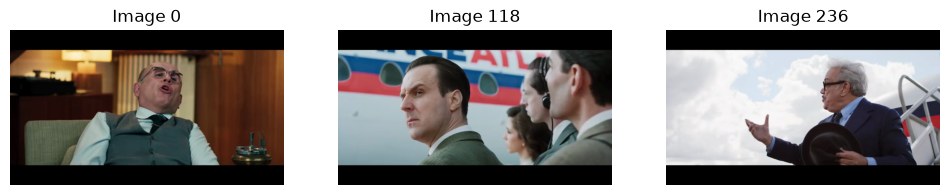

In [2]:
frames, fps = utils.frame_capture(str(TRAILER))
if len(frames) == 0 or fps <= 0:
    raise ValueError('Vidéo vide ou FPS invalides')
h, w, effective_area, _, _ = utils.compute_params(frames, MOVIE_ID, mode='infer')
detections = vision_detection.detect_faces(MOVIE_ID, frames, h, w, BATCH_SIZE, device, 2,
                                          bbox_expand_factor=BBOX_EXPAND_FACTOR)
print(f'{len(frames)} images, {len(detections)} visages, {len(frames)/fps:.2f} secondes')
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, index in zip(axes, np.linspace(0, len(frames)-1, 3, dtype=int)):
    ax.imshow(cv2.cvtColor(frames[index], cv2.COLOR_BGR2RGB))
    ax.set_title(f'Image {index}')
    ax.axis('off')
plt.show()

## Sélection et inspection
La suppression optionnelle conserve les grandes boîtes d’une même image. Elle utilise les boîtes originales et peut supprimer des visages distincts proches : inspecter son effet.

111 / 826 détections conservées


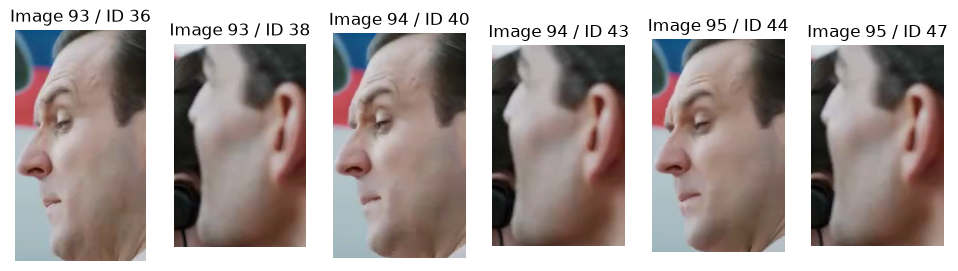

In [3]:
selected = filter_detections.filter_detections_clustering(
    detections, effective_area, MIN_AREA, MAX_AREA, MIN_CONF,
    remove_overlaps=REMOVE_OVERLAPS, iou_threshold=IOU_THRESHOLD)
print(f'{len(selected)} / {len(detections)} détections conservées')
if not selected:
    raise ValueError('Aucun visage retenu ; inspecter les seuils avant de continuer')
fig, axes = plt.subplots(1, min(6, len(selected)), figsize=(12, 3), squeeze=False)
for ax, det in zip(axes[0], selected):
    ax.imshow(cv2.cvtColor(det['cropped_face'], cv2.COLOR_BGR2RGB))
    ax.set_title(f"Image {det['frame_id']} / ID {det['perso_id']}")
    ax.axis('off')
plt.show()

## Classification, pondération et embeddings
Les poids de vote utilisent confiance YOLO, netteté et pose. Les prédictions sont des estimations. Les conversions BGR/RGB historiques restent à évaluer.

In [4]:
classified, crops, perso_ids = vision_classifiers.classify_faces(selected, BATCH_SIZE, device)
weighted = filter_detections.filter_detections_classifications(
    classified, effective_area, 0.8059752338758108, 144.39764905212095,
    -0.18154759434262552, 0.0, movie_id=MOVIE_ID)
embeddings = faces_clustering.embed_faces(crops, BATCH_SIZE, device)
assert len(embeddings) == len(weighted) == len(perso_ids)
assert perso_ids == [det['perso_id'] for det in weighted]
display(pd.DataFrame(weighted)[['perso_id', 'frame_id', 'gender', 'age', 'ethnicity', 'classification_weight']].head(10))

I0000 00:00:1792166321.584589 5738866 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 91.7), renderer: Apple M5
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792166321.593602 5740708 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792166321.599362 5740711 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792166321.602586 5740711 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


,perso_id,frame_id,gender,age,ethnicity,classification_weight
0,36,93,Male,unknown,White,1
1,38,93,unknown,unknown,White,0
2,40,94,Male,unknown,White,1
3,43,94,unknown,unknown,White,0
4,44,95,Male,unknown,White,1
5,47,95,unknown,unknown,White,0
6,48,96,Male,unknown,White,1
7,51,96,unknown,unknown,White,0
8,52,97,Male,unknown,White,1
9,55,97,unknown,unknown,White,0


## Groupes et temps de présence
Chinese Whispers regroupe les embeddings. Le temps additionne les détections/FPS, pas les images uniques. Les identifiants de groupe ne constituent pas des identités annotées.

,label,gender,age,ethnicity,time_on_screen,average_size_on_screen
0,0,Male,20-29,White,1.458333,0.117918
1,1,unknown,unknown,White,2.625000,0.113296
2,2,unknown,20-29,White,0.541667,0.086459


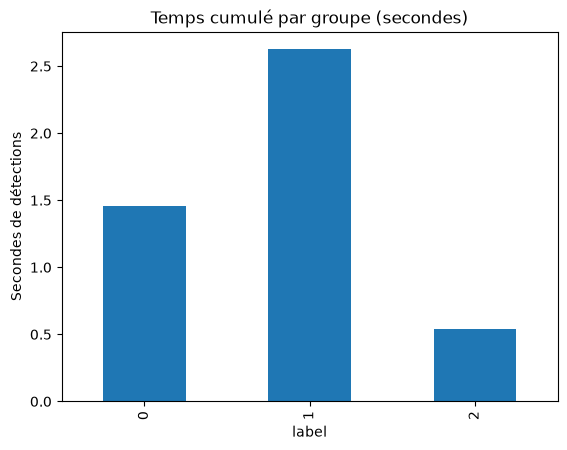

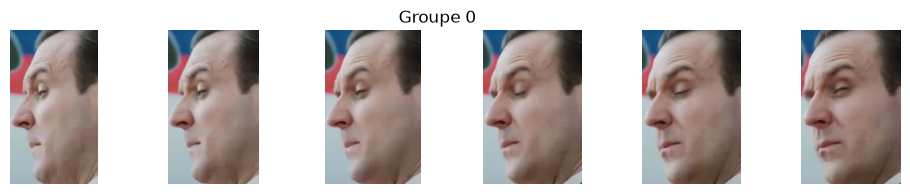

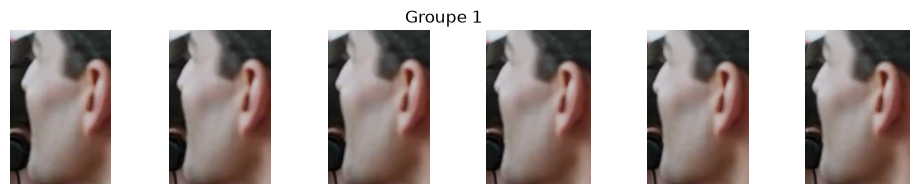

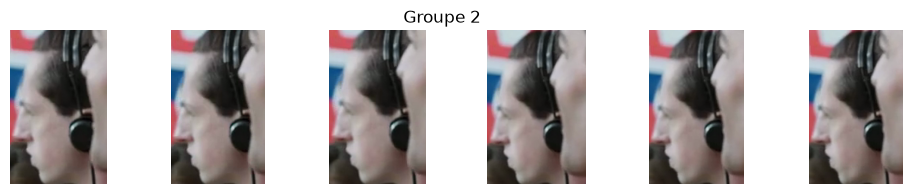

365

In [5]:
characters = faces_clustering.cluster_faces(
    embeddings, 'chinese_whispers', CLUSTER_THRESHOLD, weighted, 'majority', fps, effective_area)
if not characters:
    raise ValueError('Aucun groupe conservé')
results = pd.DataFrame([dict(label=c['label'], gender=c['gender'], age=c['age'],
                            ethnicity=c['ethnicity'], time_on_screen=c['occurence'],
                            average_size_on_screen=c['area occupied']) for c in characters])
display(results)
results.plot.bar(x='label', y='time_on_screen', legend=False, title='Temps cumulé par groupe (secondes)')
plt.ylabel('Secondes de détections')
plt.show()
# Inspection de membres : utile pour repérer fusions et séparations erronées.
by_id = {det['perso_id']: det for det in weighted}
for character in characters[:6]:
    members = [by_id[i] for i in character['perso_ids'][:6]]
    fig, axes = plt.subplots(1, len(members), figsize=(12, 2), squeeze=False)
    for ax, member in zip(axes[0], members):
        ax.imshow(cv2.cvtColor(member['cropped_face'], cv2.COLOR_BGR2RGB))
        ax.axis('off')
    fig.suptitle(f"Groupe {character['label']}")
    plt.show()
results.to_csv(RUN / 'characters.csv', index=False)
import json
(RUN / 'parameters.json').write_text(json.dumps(dict(
    trailer=str(TRAILER), movie_id=MOVIE_ID, device=str(device), batch_size=BATCH_SIZE,
    bbox_expand_factor=BBOX_EXPAND_FACTOR, remove_overlaps=REMOVE_OVERLAPS,
    iou_threshold=IOU_THRESHOLD, min_area=MIN_AREA, max_area=MAX_AREA,
    min_conf=MIN_CONF, cluster_threshold=CLUSTER_THRESHOLD), indent=2))

## Comparaison facultative avec les annotations

Comparer les distributions de temps par attribut sur le **même extrait**. Le score `1 − distance de variation totale` mesure uniquement leur similarité. Des personnages mal classifiés peuvent conserver exactement les mêmes proportions. Ce score ne mesure ni l’exactitude individuelle ni celle du regroupement. Vérifier aussi le temps total ; une distribution vide n’a pas de score.

In [6]:
if GROUND_TRUTH is not None:
    path = Path(GROUND_TRUTH).expanduser()
    truth = pd.read_csv(path if path.is_absolute() else ROOT / path)
    required = ['gender', 'age', 'ethnicity', 'time_on_screen']
    if not set(required).issubset(truth.columns):
        raise ValueError(f'Colonnes requises : {required}')
    for table in [truth, results]:
        if table[required].isna().any().any() or not np.isfinite(table.time_on_screen).all() or (table.time_on_screen < 0).any():
            raise ValueError('Annotations incomplètes ou durées invalides')
    print('Temps total annoté / prédit :', truth.time_on_screen.sum(), results.time_on_screen.sum())
    comparisons = []
    for attribute in ['gender', 'age', 'ethnicity']:
        reference = truth.groupby(attribute).time_on_screen.sum()
        predicted = results.groupby(attribute).time_on_screen.sum()
        if reference.sum() <= 0 or predicted.sum() <= 0:
            similarity = float('nan')
        else:
            proportions = pd.concat([reference/reference.sum(), predicted/predicted.sum()], axis=1).fillna(0)
            proportions.columns = ['Annoté', 'Prédit']
            similarity = 1 - (proportions.iloc[:, 0] - proportions.iloc[:, 1]).abs().sum()/2
            proportions.plot.bar(title=f'Distribution du temps : {attribute}')
            plt.ylabel('Fraction du temps cumulé')
            plt.show()
        comparisons.append(dict(attribut=attribute, similarite_distribution=similarity))
    display(pd.DataFrame(comparisons))
else:
    print('Sans annotations : aucune mesure de qualité calculée.')

Sans annotations : aucune mesure de qualité calculée.


## Interprétation et limites

Consigner les erreurs observées dans les crops et les groupes avant de modifier les seuils. Comparer les exécutions isolées, puis valider sur plusieurs films annotés. Les options CUDA sont disponibles dans la CLI depuis la PR 29 ; ce notebook utilise le CPU par défaut et n’active pas AMP. Le classifieur d’attributs de la PR 27 n’est pas intégré.

## Historique du document

| # | Date | Auteur | Observations |
| --- | --- | --- | --- |
| 1 | 2026-10-16 | Joel Teixeira | Consolidation des explorations de Joel (PR 27), paramètres explicites, chemins absolus et distinction entre similarité des distributions et exactitude. |
| 2 | 2026-10-16 | Joel Teixeira | Installation et sélection explicites du noyau ML, diagnostic des dépendances avant les imports et clarification du périmètre CUDA. |
